###<font color='red'>Made by Anton Rudchenko for ParKinSim (Parallel Kinematic Simulation) project.</font>


Development of a final ML model (PolynomialFeatures model) and it's validation for ParKinSim project.

In [ ]:
#@title <font color='yellow'>Imports

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.model_selection import learning_curve
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline


pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

##<font color='yellow'>Importing and preprocessing data collected from solving direct kinematics in simulation.

In [ ]:
first_dataset = "DKd.csv" #'DKd_1st.csv'
second_dataset = first_dataset#'DKd_2nd.csv'

data = pd.read_csv(first_dataset).drop_duplicates()

print(data)

labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

         L1    L2    L3    L4    L5       X        Y       Z     RX     RY  \
0      28.0  28.0  25.0  18.0  22.0   4.416  154.443  -5.407 -0.039 -0.045   
1      29.0  28.0  25.0  18.0  22.0   4.245  153.820  -2.994 -0.060 -0.047   
2      30.0  28.0  25.0  18.0  22.0   4.073  153.117  -0.569 -0.081 -0.048   
3      31.0  28.0  25.0  18.0  22.0   3.899  152.328   1.871 -0.101 -0.050   
4      32.0  28.0  25.0  18.0  22.0   3.723  151.449   4.326 -0.121 -0.052   
...     ...   ...   ...   ...   ...     ...      ...     ...    ...    ...   
14208  31.0  74.0  66.0  17.0   8.0  43.040  184.591 -43.755  0.193 -0.307   
14209  31.0  76.0  66.0  17.0   8.0  46.377  185.046 -48.261  0.242 -0.293   
14210  31.0  78.0  66.0  17.0   8.0  49.811  184.955 -52.846  0.298 -0.280   
14211  31.0  80.0  66.0  17.0   8.0  53.423  184.092 -57.574  0.367 -0.269   
14212  31.0  82.0  66.0  17.0   8.0  57.473  181.809 -62.621  0.460 -0.261   

          RZ  
0     -0.005  
1     -0.008  
2     -0.011  
3  

In [ ]:
for i in data:
  print(f"{i}: {data[i].min()} to {data[i].max()}")

L1: 2.0 to 116.0
L2: 2.0 to 116.0
L3: 2.0 to 116.0
L4: 2.0 to 116.0
L5: 2.0 to 116.0
X: -105.472 to 100.851
Y: 34.818 to 265.098
Z: -92.593 to 123.591
RX: -1.186 to 1.069
RY: -1.387 to 1.416
RZ: -1.614 to 1.78


##<font color='yellow'>Model Definition.

Performance Metrics:
Target L1:
  Mean Squared Error: 0.0175
  R2 Score: 1.0000
Target L2:
  Mean Squared Error: 0.0768
  R2 Score: 0.9999
Target L3:
  Mean Squared Error: 0.3189
  R2 Score: 0.9996
Target L4:
  Mean Squared Error: 0.3094
  R2 Score: 0.9997
Target L5:
  Mean Squared Error: 0.0685
  R2 Score: 0.9999


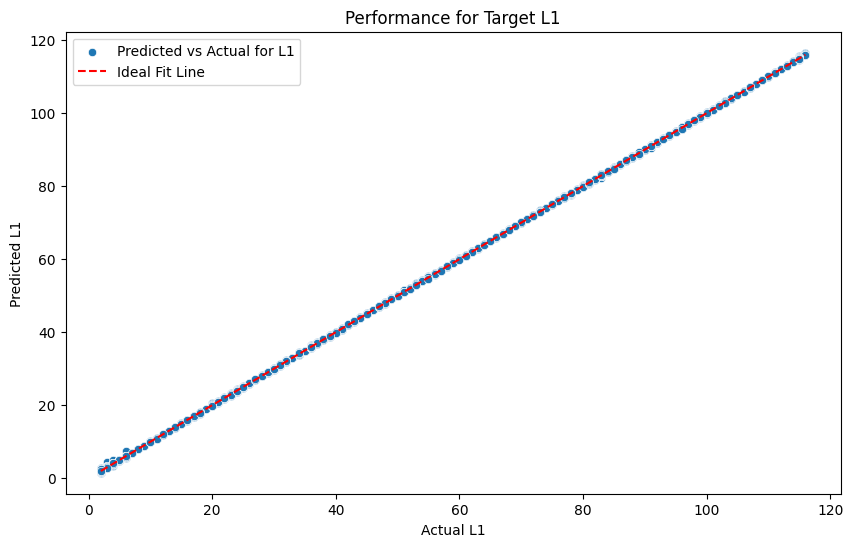

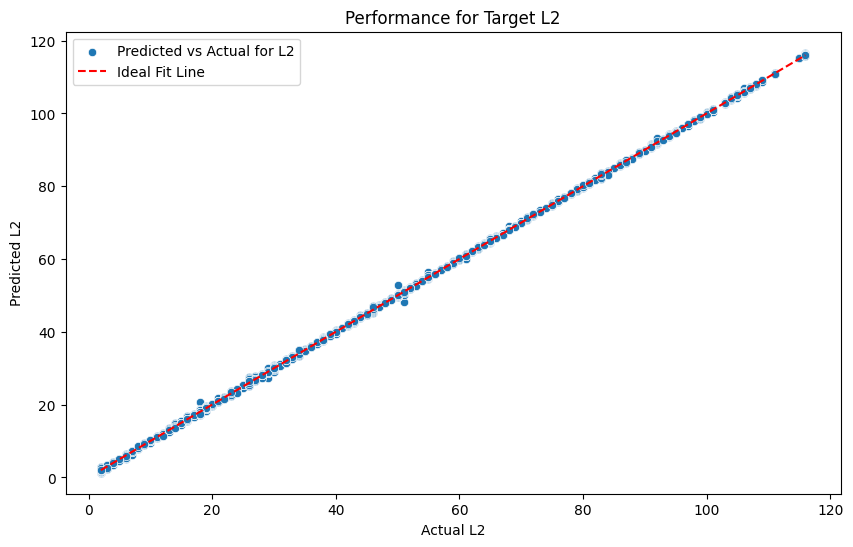

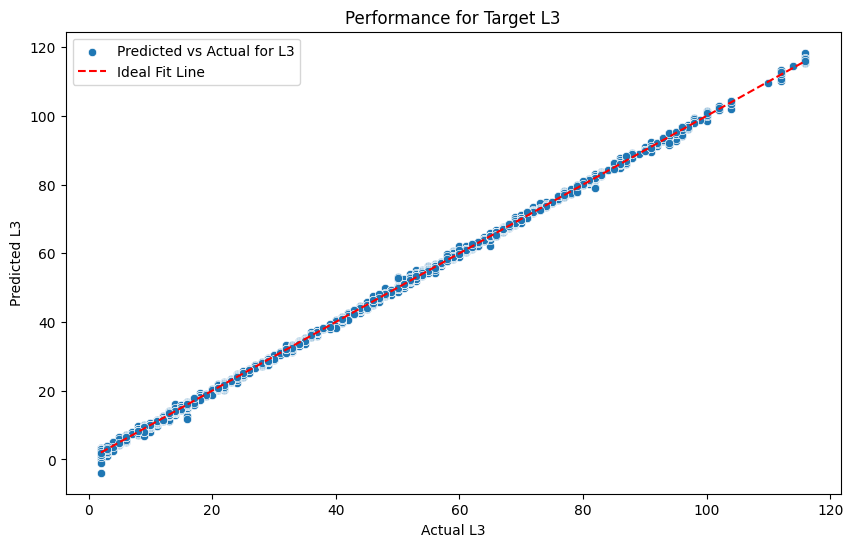

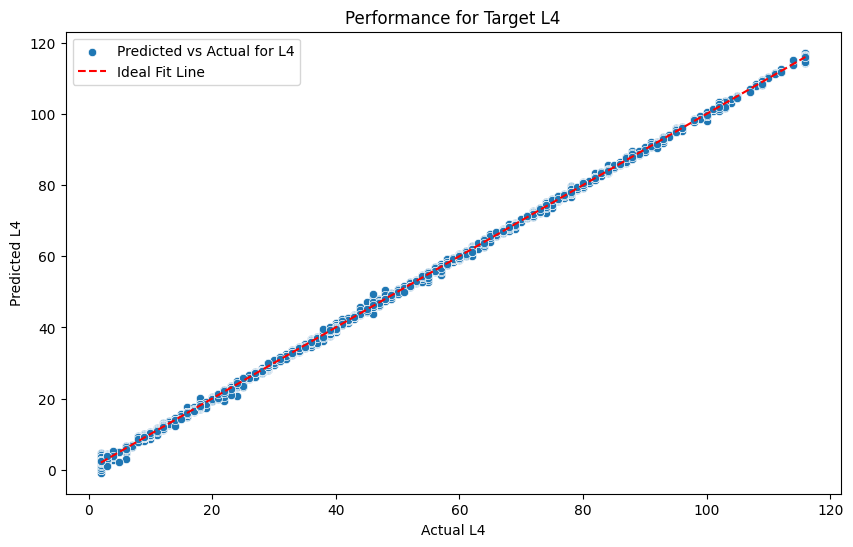

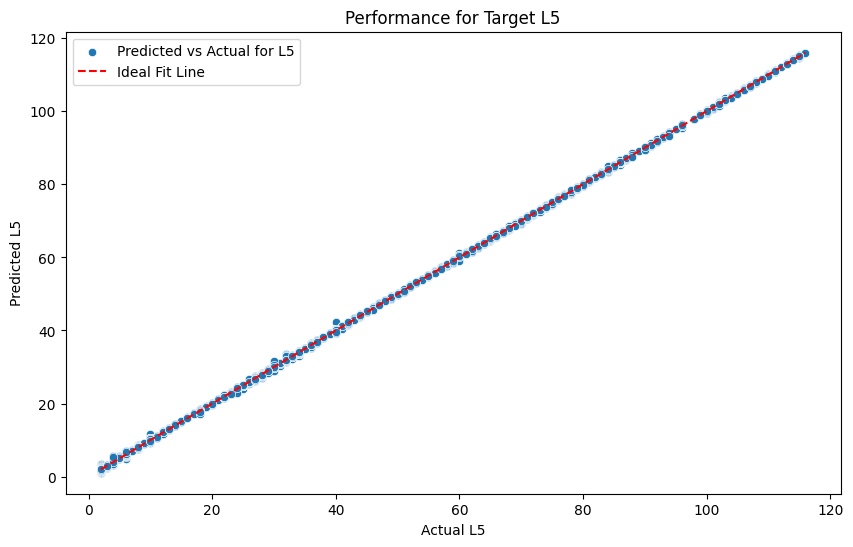

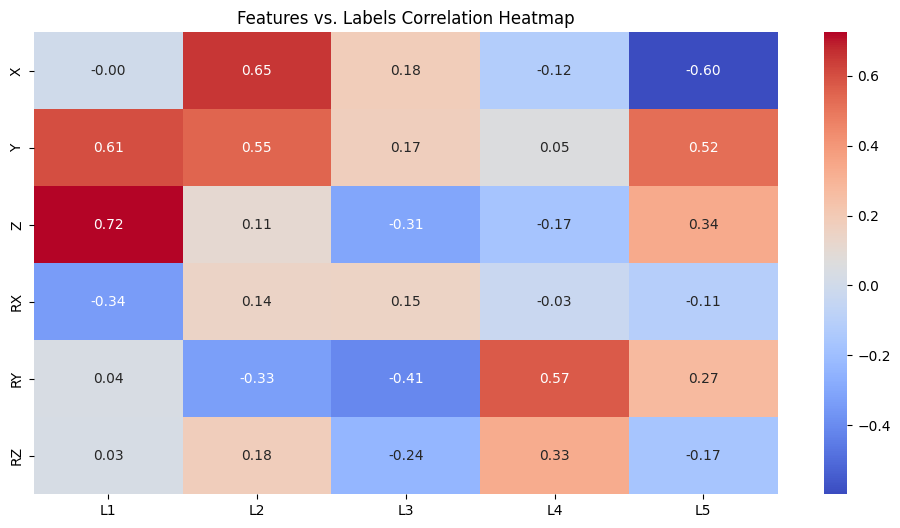

In [ ]:
degree = 4

model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))

correlation_matrix = pd.concat([features, labels], axis=1).corr()
sns.heatmap(correlation_matrix.loc[features.columns, labels.columns], annot=True, cmap='coolwarm', fmt=".2f")

plt.title("Features vs. Labels Correlation Heatmap")
plt.show()

##<font color='yellow'>Check for overfit.


Validation methods are suggested and checked with the help of ChatGPT.

In [ ]:
#@title Comparing training and test performance
y_train_pred = model.predict(X_train)
mse_train = mean_squared_error(y_train, y_train_pred, multioutput='raw_values')
r2_train = r2_score(y_train, y_train_pred, multioutput='raw_values')

mse_test = mse
r2_test = r2

for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Train MSE: {mse_train[i]:.4f}, Test MSE: {mse_test[i]:.4f}")
    print(f"  Train R2 Score: {r2_train[i]:.4f}, Test R2 Score: {r2_test[i]:.4f}")

    # Check for Overfitting
    if r2_train[i] > 0.9 and r2_test[i] < 0.7:
        print(f"⚠️ Potential Overfitting Detected for Target {target}")


Target L1:
  Train MSE: 0.0154, Test MSE: 0.0175
  Train R2 Score: 1.0000, Test R2 Score: 1.0000
Target L2:
  Train MSE: 0.0664, Test MSE: 0.0768
  Train R2 Score: 0.9999, Test R2 Score: 0.9999
Target L3:
  Train MSE: 0.2884, Test MSE: 0.3189
  Train R2 Score: 0.9996, Test R2 Score: 0.9996
Target L4:
  Train MSE: 0.2958, Test MSE: 0.3094
  Train R2 Score: 0.9997, Test R2 Score: 0.9997
Target L5:
  Train MSE: 0.0592, Test MSE: 0.0685
  Train R2 Score: 0.9999, Test R2 Score: 0.9999


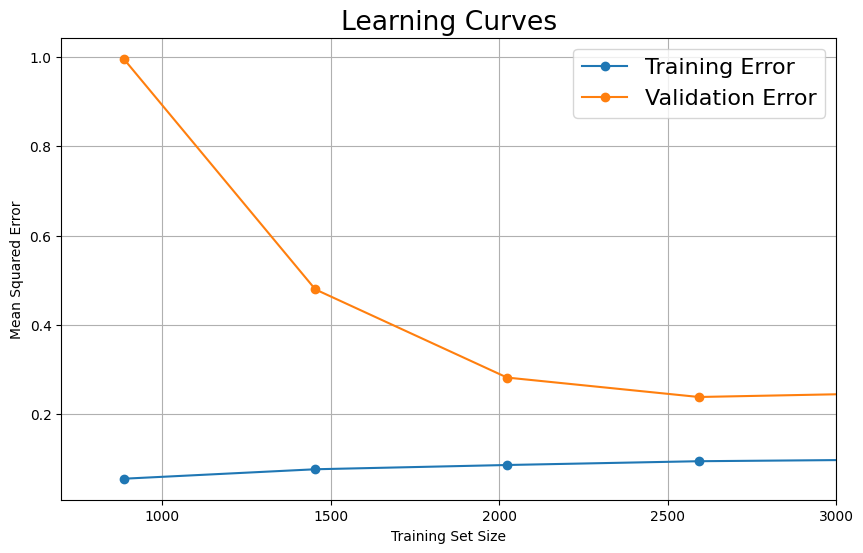

In [ ]:
#@title Ploting learning curves

#train_sizes, train_scores, test_scores = learning_curve(
#    model, X_train, y_train, cv=5, scoring='neg_mean_squared_error'
#)
from numpy import linspace
train_sizes, train_scores, test_scores = learning_curve(
    model,
    X_train,
    y_train,
    train_sizes=linspace(0.1, 1.0, 15),
    cv=5,
    scoring='neg_mean_squared_error'
)

train_scores_mean = -train_scores.mean(axis=1)
test_scores_mean = -test_scores.mean(axis=1)

plt.figure(figsize=(10, 6))
plt.xlim(left=700, right=3000) # Added the latest
plt.rcParams.update({'font.size': 14}) # Added the latest
plt.plot(train_sizes, train_scores_mean, label="Training Error", marker='o')
plt.plot(train_sizes, test_scores_mean, label="Validation Error", marker='o')
plt.rcParams.update({'font.size': 16}) # Added the latest
plt.xlabel('Training Set Size')
plt.ylabel('Mean Squared Error')
plt.title('Learning Curves')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
#@title Cross Validation.

cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
print(f"Cross-Validation R² Scores: {cv_scores}")
print(f"Mean R² Score: {cv_scores.mean():.4f}")

Cross-Validation R² Scores: [0.99982183 0.99973044 0.99981199 0.99981791 0.9998249 ]
Mean R² Score: 0.9998


###<font color='red'>Conclusion:</font> results are surprisingly good, methods for checking the model for overfit have not detected any. May be that the data is too easy for this model.

###<font color='red'>Note:</font> Also regularization was applied but no significatn change observed.

##<font color='yellow'>Exporting the model.

In [ ]:
import joblib

joblib.dump(model, 'PF_model.pkl')

['PF_model.pkl']

##<font color='yellow'>Interface for loading the model.

In [ ]:
import joblib

# Load the model
model = joblib.load('PF_model.pkl')
print("Model loaded successfully!")

# Example: Make predictions

feature_names = ['X', 'Y', 'Z', 'RX', 'RY', 'RZ']

test = np.array([
    [0, 150, 10, 0, 0, 0],
    ])

X_test = pd.DataFrame(test, columns=feature_names)

y_pred = model.predict(X_test)
print(y_pred.round(0))


Model loaded successfully!
[[41. 28.  7.  7. 31.]]


<font color=red> Remark:  </font> Any prediction elements with minus sign are incorrect, as LA cannot go below zero.

##<font color='yellow'>Testing model on unseen dataset

In [ ]:
import sys
#sys.exit()
dkd_2nd = pd.read_csv(second_dataset).drop_duplicates()

labels_2nd = dkd_2nd[['L1', 'L2', 'L3', 'L4', 'L5']]
features_2nd = dkd_2nd[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

labels_2nd.describe()

,L1,L2,L3,L4,L5
count,13836.000000,13836.000000,13836.000000,13836.000000,13836.000000
mean,55.525224,48.995880,47.028766,44.772044,48.668257
std,34.688011,32.118162,28.002213,30.336786,32.408456
min,2.000000,2.000000,2.000000,2.000000,2.000000
25%,29.000000,23.000000,22.000000,21.000000,24.000000
50%,52.000000,43.000000,51.000000,42.000000,43.000000
75%,88.000000,77.000000,67.000000,64.000000,74.000000
max,116.000000,116.000000,116.000000,116.000000,116.000000


In [ ]:
y_pred = model.predict(features_2nd)

labels_names = ['L1', 'L2', 'L3', 'L4', 'L5']
predictions = pd.DataFrame(y_pred, columns=labels_names)

predictions = predictions.round(0)
print(predictions)

labels_2nd = labels_2nd.round(0)
print(labels_2nd)

         L1    L2    L3    L4    L5
0      28.0  28.0  25.0  18.0  22.0
1      29.0  28.0  25.0  18.0  22.0
2      30.0  28.0  25.0  18.0  22.0
3      31.0  28.0  25.0  18.0  22.0
4      32.0  28.0  25.0  18.0  22.0
...     ...   ...   ...   ...   ...
13831  31.0  74.0  66.0  17.0   8.0
13832  31.0  76.0  67.0  17.0   8.0
13833  31.0  78.0  67.0  17.0   8.0
13834  31.0  80.0  67.0  17.0   8.0
13835  31.0  82.0  67.0  16.0   8.0

[13836 rows x 5 columns]
         L1    L2    L3    L4    L5
0      28.0  28.0  25.0  18.0  22.0
1      29.0  28.0  25.0  18.0  22.0
2      30.0  28.0  25.0  18.0  22.0
3      31.0  28.0  25.0  18.0  22.0
4      32.0  28.0  25.0  18.0  22.0
...     ...   ...   ...   ...   ...
14208  31.0  74.0  66.0  17.0   8.0
14209  31.0  76.0  66.0  17.0   8.0
14210  31.0  78.0  66.0  17.0   8.0
14211  31.0  80.0  66.0  17.0   8.0
14212  31.0  82.0  66.0  17.0   8.0

[13836 rows x 5 columns]


In [ ]:
#@title Plot fucntion for comparison dataframe


def plot_comparison(coll, x_lim = 0, y_lim = 0):
    act = coll["self"].dropna(axis=0, how='all')
    pred = coll["other"].dropna(axis=0, how='all')

    x_a = range(0, act.shape[0])
    y_a = act
    x_p = range(0, pred.shape[0])
    y_p = pred


    # Create a new plot
    plt.figure(figsize=(10, 6))

    # Plot the 'self' and 'other' values for comparison
    plt.plot(x_a, y_a, marker='o', label='Actual', color='blue')
    plt.plot(x_p, y_p, marker='o', label='Predicted', color='red')

    # Add labels, title, and legend
    plt.xlabel('Labels')
    plt.ylabel('Values')
    plt.title('"Actual" vs "Predicted"')
    plt.legend()
    plt.grid(True)

    if x_lim != 0:
        plt.xlim(x_lim[0], x_lim[1])  # X-axis range from 0 to 6
    if y_lim != 0:
        plt.ylim(y_lim[0], y_lim[1])  # Y-axis range from 0 to 25

    # Show the plot
    plt.show()

In [ ]:
# comp = labels_2nd.compare(predictions)
# print(comp)


Here in comparison NaN means that values are equal in "self" and "other" columns.

In [ ]:
# print(comp.isna().sum())

So the more NaNs, the better. Here above, we can see that L3 and L4 have very small number of NaNs per dataframe size, which states that those values were not predicted 100% correctly.

Another question - is how much is the difference between actual and predicted values?

In [ ]:
# temp = [["L1", "L2", "L3", "L4", "L5"], [[[130, 170], [0, 40]], [[425, 500], [15, 55]], [[1000, 1050], [30, 85]], [[1360, 1420], [18, 56]], [[500, 570], [0, 60]]]]

# for i,j in zip(temp[0], temp[1]):
#   print('\n' + '*'*50 + i)
#   plot_comparison(comp[i], j[0], j[1])
# #plot_comparison(comp["L1"], [130, 170], [0, 40])

##<font color=yellow> Conclusion

The data needs to be filtered better, with considerations of how the mechanics work! The thing is that some configurations are broken, even that the simulation didn't give any errors and recorded them, they still need to be removed manually.

But all in all, this controll system should be enough to prove the concept works!